# Campus Electricity Demand & Flexibility (Person 4)

**Output:** `data/processed/demand_hourly.csv`, which has 8,760 rows aligned with `Solar PV data.csv` (Jan 1 → Dec 31, `Hour` 1–24 hour-ending).
Columns: hourly demand plus the flexibility bounds used in the MILP.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "demand" else Path.cwd()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df"})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

## 1. Load and clean
The raw data is UW-Total meter readings every 15 minutes, Oct 1 2025 – Sep 30 2026. Each timestamp marks the **end** of its interval, and `24:00:00` means midnight of the next day.

In [2]:
raw = pd.read_csv(ROOT / "data" / "DemandProfile_UW .csv", skiprows=1)
hm = raw["TIME"].str.split(":", expand=True)[[0, 1]].astype(int)
raw["ts_end"] = pd.to_datetime(raw["DATE"], format="%d-%b-%y") + pd.to_timedelta(hm[0], "h") + pd.to_timedelta(hm[1], "min")

print("rows:", len(raw), "| expected:", 365 * 96, "| missing values:", raw["kW"].isna().sum(),
      "| evenly spaced:", raw["ts_end"].diff().dropna().eq(pd.Timedelta("15min")).all())

rows: 35040 | expected: 35040 | missing values: 0 | evenly spaced: True


The data is complete. Two short **load-loss events** (partial outages) appear: one on Jun 11 2026, when load fell to 4.8 MW, and one on Oct 22 2025.
They reflect supply problems, not what the campus needs, so they're replaced. Each reading is compared with the median of the same 15-minute slot on days −7, −1, +1 and +7. Readings below 75 % of that median are flagged, and the flag is extended into neighbouring readings still below 90 %.

In [3]:
k = raw["kW"].to_numpy().reshape(365, 96)
ref = np.array([np.median([k[d + o] for o in (-7, -1, 1, 7) if 0 <= d + o < 365], axis=0) for d in range(365)])
ratio = (k / ref).ravel()
flag = ratio < 0.75
while True:  # extend each event into adjacent still-depressed readings
    grow = (np.r_[False, flag[:-1]] | np.r_[flag[1:], False]) & ~flag & (ratio < 0.90)
    if not grow.any(): break
    flag |= grow
raw["kW_clean"] = np.where(flag, ref.ravel(), raw["kW"])
print(f"repaired {flag.sum()} of {flag.size} readings")
raw.loc[flag, ["ts_end", "kW", "kW_clean"]]

repaired 18 of 35040 readings


,ts_end,kW,kW_clean
2048,2025-10-22 08:15:00,9796.6,11285.10
2049,2025-10-22 08:30:00,6986.6,11407.20
2050,2025-10-22 08:45:00,7197.1,11532.65
2051,2025-10-22 09:00:00,7356.2,11669.25
2052,2025-10-22 09:15:00,9480.8,11798.10
24373,2026-06-11 21:30:00,4858.6,11309.20
24374,2026-06-11 21:45:00,4821.6,11270.00
24375,2026-06-11 22:00:00,5642.6,11212.90
24376,2026-06-11 22:15:00,5458.9,10716.75
24377,2026-06-11 22:30:00,5416.3,10626.55


## 2. Convert to hourly
Hourly demand is the mean of the four 15-minute readings in the hour, which equals the kWh used in that hour. Rows are then reordered Jan 1 → Dec 31, using Jan–Sep from 2026 and Oct–Dec from 2025, so they line up with the solar file.

In [4]:
hour_start = (raw["ts_end"] - pd.Timedelta("1ns")).dt.floor("h")
h = raw.groupby(hour_start)["kW_clean"].mean().rename("demand_kW").rename_axis("ts").reset_index()
h["Month"], h["Day"], h["Hour"] = h.ts.dt.month, h.ts.dt.day, h.ts.dt.hour + 1
h["working_day"] = h.ts.dt.dayofweek < 5
h["season"] = h.Month.map(lambda m: ["Winter", "Spring", "Summer", "Fall"][(m % 12) // 3])
h = h.sort_values(["Month", "Day", "Hour"]).reset_index(drop=True)
h.insert(0, "t", np.arange(1, 8761)); h.insert(1, "d", (h.t - 1) // 24 + 1)

solar = pd.read_csv(ROOT / "data" / "Solar PV data.csv")
assert len(h) == 8760 and (h[["Month", "Day", "Hour"]].values == solar[["Month", "Day", "Hour"]].values).all()
assert np.isclose(h.demand_kW.sum(), raw.kW_clean.sum() / 4)   # energy conserved
print("aligned with solar file; annual energy conserved")

aligned with solar file; annual energy conserved


## 3. Demand patterns

In [5]:
D = h.demand_kW
pd.Series({"Annual energy (MWh)": round(D.sum() / 1e3),
           "Average (MW)": round(D.mean() / 1e3, 2),
           "Peak (MW)": round(D.max() / 1e3, 2), "Peak hour starts": h.ts[D.idxmax()],
           "Minimum (MW)": round(D.min() / 1e3, 2), "Min hour starts": h.ts[D.idxmin()],
           "Load factor": round(D.mean() / D.max(), 2)}).to_frame("value")

,value
Annual energy (MWh),96948
Average (MW),11.07
Peak (MW),16.53
Peak hour starts,2026-07-02 12:00:00
Minimum (MW),8.33
Min hour starts,2025-12-29 04:00:00
Load factor,0.67


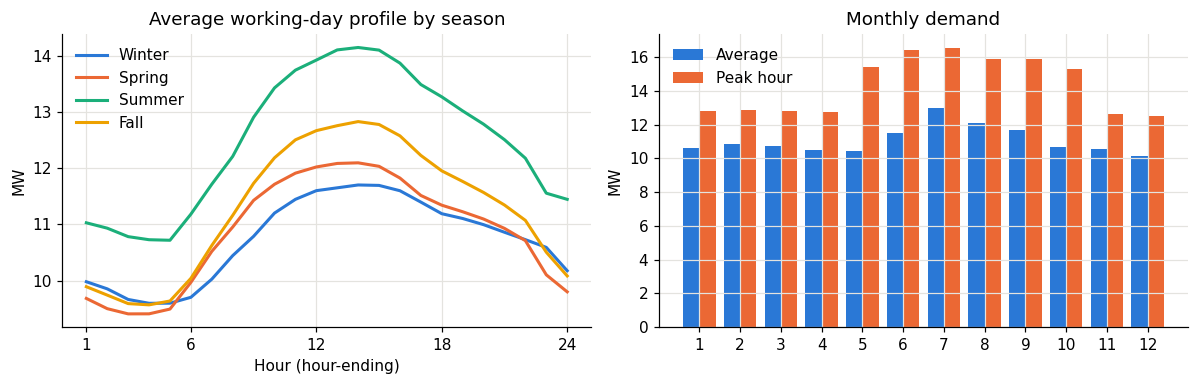

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for i, s in enumerate(["Winter", "Spring", "Summer", "Fall"]):
    p = h[h.working_day & (h.season == s)].groupby("Hour").demand_kW.mean() / 1e3
    axes[0].plot(p.index, p, color=C[i], lw=2, label=s)
axes[0].set(title="Average working-day profile by season", xlabel="Hour (hour-ending)", ylabel="MW", xticks=[1, 6, 12, 18, 24])
axes[0].legend(frameon=False)
m = h.groupby("Month").demand_kW.agg(["mean", "max"]) / 1e3
axes[1].bar(m.index - 0.2, m["mean"], 0.4, color=C[0], label="Average")
axes[1].bar(m.index + 0.2, m["max"], 0.4, color=C[1], label="Peak hour")
axes[1].set(title="Monthly demand", ylabel="MW", xticks=range(1, 13))
axes[1].legend(frameon=False); plt.tight_layout()

**Findings**
- **High hours:** on working days demand is highest **10:00–17:00** and peaks around **13:00–14:00**. **Low hours:** **02:00–05:00**.
- **Seasonal:** demand **peaks in summer** (June–August averages about 12.2 MW, against about 10.5 MW in winter), because cooling is electric and heating is gas. All of the highest hours fall at midday in June or July, the same time solar output is highest.
- The overnight base load is about 9–11 MW, roughly 80 % of the average. Most campus load runs 24/7 and can't be shifted.
- Weekends and the winter closure (late December) are the lowest-demand periods.

## 4. Future demand
$$D_{y,t} = D_t\,(1+g)^{\,y-2026}, \qquad y = 2027,\dots,2046$$

The data year counts as 2026. Every hour is scaled by the same factor, so the shape of the profile stays the same.

| Case | $g$ | Rationale |
|---|---|---|
| Low | 1 %/yr | Efficiency-led, slow campus growth |
| **Base** | **2 %/yr** | IESO 2026 Annual Planning Outlook: Ontario demand about **2.1 %/yr** over 2026–2050 |
| High | 3 %/yr | UW's own trend of about 3.5 %/yr (2013/14–2018/19, CDM Plan 2024) plus heat-pump electrification under Shift:Neutral |

In [7]:
years = np.array([2027, 2032, 2037, 2042, 2046])
pd.DataFrame({f"{g:.0%}": (D.max() / 1e3) * (1 + g) ** (years - 2026) for g in (0.01, 0.02, 0.03)},
             index=pd.Index(years, name="Peak MW in year")).round(1)

,1%,2%,3%
Peak MW in year,,,
2027,16.7,16.9,17.0
2032,17.6,18.6,19.7
2037,18.4,20.6,22.9
2042,19.4,22.7,26.5
2046,20.2,24.6,29.9


## 5. Demand flexibility
**Assumptions**
1. In any hour, demand can move up or down by at most $\alpha = 10\%$ of that hour's demand.
2. Each day's total energy stays the same: load is moved, not removed.
3. **Critical load is protected.** Each day's minimum hourly demand $C_t$ (labs, data centres, ventilation running 24/7) is never reduced.
4. **No new peak.** Shifting can't push demand above the year's peak $P^{\max}$.

**Precomputed bounds** (parameters, so the model stays linear):
$$\overline F^{-}_t = \min\{\alpha D_t,\ D_t - C_t\},\qquad \overline F^{+}_t = \min\{\alpha D_t,\ P^{\max} - D_t\}$$

**Variable:** $s_t \in \mathbb R$, the net shift in hour $t$ (kWh).

$$
\begin{aligned}
L_t &= D_t + s_t && \forall t \quad\text{(served demand: use } L_t \text{ in the energy balance)}\\
-\overline F^{-}_t \le s_t &\le \overline F^{+}_t && \forall t\\
\textstyle\sum_{t \in T_d} s_t &= 0 && \forall d \in \{1,\dots,365\}
\end{aligned}
$$

These constraints need no binary variables. In a future year, scale $D_t$, $C_t$, $\overline F^{\pm}_t$ and $P^{\max}$ by $(1+g)^{y-2026}$.

In [8]:
alpha = 0.10
crit = h.groupby("d").demand_kW.transform("min")
h["flex_down_max_kW"] = np.minimum(alpha * D, D - crit)
h["flex_up_max_kW"] = np.minimum(alpha * D, D.max() - D)
print(f"average allowed decrease: {(h.flex_down_max_kW / D).mean():.1%} of demand (the critical floor binds at night)")
print(f"average allowed increase: {(h.flex_up_max_kW / D).mean():.1%} of demand")

average allowed decrease: 7.1% of demand (the critical floor binds at night)
average allowed increase: 9.9% of demand


## 6. Save

In [9]:
out = ROOT / "data" / "processed"; out.mkdir(parents=True, exist_ok=True)
cols = ["t", "d", "Month", "Day", "Hour", "demand_kW", "flex_down_max_kW", "flex_up_max_kW"]
h[cols].round(2).to_csv(out / "demand_hourly.csv", index=False)
h[cols].head()

,t,d,Month,Day,Hour,demand_kW,flex_down_max_kW,flex_up_max_kW
0,1,1,1,1,1,9407.975,139.975,940.7975
1,2,1,1,1,2,9401.000,133.000,940.1000
2,3,1,1,1,3,9323.750,55.750,932.3750
3,4,1,1,1,4,9284.250,16.250,928.4250
4,5,1,1,1,5,9268.000,0.000,926.8000


**Sources:** [IESO APO 2026](https://www.ieso.ca/-/media/Files/IESO/Document-Library/planning-forecasts/apo/2026/2026-Annual-Planning-Outlook.pdf) ·
[UW CDM Plan 2024](https://uwaterloo.ca/plant-operations/sites/default/files/uploads/documents/energy-conservation-and-demand-management-plan-year2024.pdf) ·
[UW Shift: Neutral](https://uwaterloo.ca/sustainability/sites/default/files/uploads/documents/shift_neutral_final_aoda.pdf)